# Materi 15 — Klasifikasi Lahan Persawahan Berbasis Citra Sentinel-2A dan Random Forest

Notebook ini berfokus pada pengolahan citra satelit **Sentinel-2A Level-2A** untuk memisahkan tutupan lahan menjadi **dua kelas utama**, yakni lahan sawah dan non-sawah. Citra akan ditarik secara otomatis dari **Copernicus Data Space** (berformat GeoTIFF). Proses pengenalan pola mengandalkan algoritma **Random Forest** dari library `scikit-learn`, yang kemudian menghasilkan luaran berupa peta spasial.

## Pemenuhan Syarat Tugas

| Kriteria Tugas | Implementasi dalam Notebook |
| --- | --- |
| **50 Sampel Kelas Sawah** | Mengambil tepat 50 poligon dari `data/sawah/input.shp` (Label Kelas: 1) |
| **50 Sampel Kelas Non-Sawah** | Mengambil tepat 50 poligon dari `data/bukansawah/input.shp` (Label Kelas: 0) |
| **Klasifikasi Biner (2 Kelas)** | Label 1 untuk Sawah, Label 0 untuk Non-Sawah |
| **Data Sentinel-2A Format TIF** | Mengunduh otomatis citra L2A, 6 band reflektansi, resolusi 10m dalam ekstensi `.tif` |

## Garis Besar Tahapan
1. Inisialisasi library dan konfigurasi parameter global.
2. Ekstraksi koordinat sampel dari file Shapefile (SHP) dan penentuan Bounding Box area.
3. Permintaan data (download) citra Sentinel-2A via Copernicus API.
4. Parsing citra GeoTIFF ke dalam matriks numerik.
5. Perhitungan indeks vegetasi dan air (NDVI, NDWI, NDBI, EVI) sebagai penambah fitur.
6. Pemetaan poligon ke dalam grid piksel citra (Rasterization).
7. Pemecahan data (Train/Test Split) berdasarkan poligon.
8. Pelatihan model klasifikasi Random Forest beserta evaluasi akurasinya.
9. Klasifikasi piksel seluruh peta.
10. Ekspor hasil akhir menjadi GeoTIFF baru beserta visualisasi gambar.

## 0. Tahap Persiapan

Library yang wajib Anda siapkan di sistem Anda:
```bash
pip install requests rasterio scikit-learn numpy matplotlib geopandas shapely
```

**Konfigurasi Akun Copernicus:**
1. Silakan buat akun di [Copernicus Data Space Dashboard](https://shapps.dataspace.copernicus.eu/dashboard).
2. Navigasi ke menu *User settings -> OAuth clients -> Create*.
3. Dapatkan **Client ID** dan **Client Secret** Anda.
4. Anda akan diminta untuk memasukkannya ke dalam *prompt* saat menjalankan sel pengunduhan data (jika file TIF belum ada).


In [ ]:
# Jika belum terinstall, silakan uncomment dan jalankan
# %pip install requests rasterio scikit-learn numpy matplotlib geopandas shapely


## 1. Memuat Library dan Menyiapkan Parameter

Pada tahap ini, kita memuat semua alat bantu komputasi dan mengatur variabel-variabel krusial. Pemusatan konfigurasi di satu blok kode akan memudahkan kita jika ingin bereksperimen dengan tanggal atau koordinat yang berbeda.

In [2]:
import os
import math
import getpass
import datetime as dt
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import geopandas as gpd
from shapely.geometry import mapping, shape, box as shp_box
import rasterio
from rasterio import features
from rasterio.warp import transform_bounds, transform_geom
import requests

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, cohen_kappa_score, precision_recall_fscore_support

DIR_SAAT_INI = Path.cwd()


In [3]:
# ==========================================
# KONFIGURASI PENCARIAN & FILTER CITRA
# ==========================================
TANGGAL_MULAI = "2026-06-01"
TANGGAL_AKHIR = "2026-09-30"
KODE_SATELIT = "S2A"
MAKS_AWAN_PERSEN = 30
MAKS_PERCOBAAN_SCENE = 5
AMBANG_VALID = 0.90
MASKING_AWAN = True
MARGIN_METER = 1500

# ==========================================
# KONFIGURASI SAMPEL & RANDOM FOREST
# ==========================================
JUMLAH_SAMPEL_PER_KELAS = 50
# Path relatif mengarah ke ../data/ (satu level di luar folder materi)
PATH_SAWAH = DIR_SAAT_INI.parent / "data" / "sawah" / "input.shp"
PATH_NON_SAWAH = DIR_SAAT_INI.parent / "data" / "bukansawah" / "input.shp"

RASIO_LATIH = 0.70
JUMLAH_POHON = 200
ANGKA_RANDOM = 42

# ==========================================
# KONFIGURASI FILE OUTPUT & API
# ==========================================
CITRA_MENTAH_TIF = DIR_SAAT_INI / "sentinel2_mentah.tif"
INFO_CITRA_TXT = DIR_SAAT_INI / "info_sentinel.txt"

HASIL_TIF = DIR_SAAT_INI / "hasil_klasifikasi_sawah.tif"
HASIL_GAMBAR = DIR_SAAT_INI / "peta_klasifikasi_sawah.png"
HASIL_TEKS = DIR_SAAT_INI / "laporan_evaluasi.txt"

NAMA_BAND = ["B02", "B03", "B04", "B08", "B11", "B12"]

URL_OAUTH = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
URL_PENCARIAN = "https://sh.dataspace.copernicus.eu/api/v1/catalog/1.0.0/search"
URL_PROSES = "https://sh.dataspace.copernicus.eu/api/v1/process"

REKAMAN_LOG = []
def catat_log(*pesan):
    teks = " ".join(str(p) for p in pesan)
    print(teks)
    REKAMAN_LOG.append(teks)


## 2. Pengambilan Sampel dari Shapefile (Area Latih & Uji)

Kita akan mengekstrak data spasial dari format `.shp`. Setiap file akan kita standarisasi ke sistem koordinat geografi standar **(WGS-84 / EPSG:4326)**. Jika jumlah poligon melebihi target, algoritma akan mengambil 50 sampel secara acak agar komposisi kelas seimbang.

Sembari mengekstrak koordinat, kita juga akan menghitung batas terluar (*Bounding Box*) dengan kelonggaran margin sebesar `MARGIN_METER` (1500 meter). Bounding Box ini mencegah kita mengunduh seluruh *scene* citra yang berat, cukup area studi ini saja.

In [4]:
def muat_geometri_sampel(jalur_file, target_n):
    data_shp = gpd.read_file(jalur_file)
    total_awal = len(data_shp)
    
    # Singkirkan data kosong
    data_shp = data_shp[data_shp.geometry.notna()].copy()
    
    # Penyeragaman CRS ke EPSG:4326
    if data_shp.crs is None:
        catat_log(f"INFO: {Path(jalur_file).name} CRS tidak ditemukan. Menggunakan fallback EPSG:4326.")
    elif data_shp.crs.to_epsg() != 4326:
        data_shp = data_shp.to_crs(epsg=4326)
        
    # Sampling acak jika over-target
    if len(data_shp) > target_n:
        generator = np.random.default_rng(ANGKA_RANDOM)
        index_acak = generator.choice(len(data_shp), target_n, replace=False)
        data_shp = data_shp.iloc[sorted(index_acak)].copy()
    
    catat_log(f"[{Path(jalur_file).name}] Total asli: {total_awal} poligon | Dipilih: {len(data_shp)} poligon")
    return [mapping(geo) for geo in data_shp.geometry]

def ektrak_titik(struktur_koordinat):
    if isinstance(struktur_koordinat[0], (int, float)):
        yield struktur_koordinat[0], struktur_koordinat[1]
    else:
        for elemen in struktur_koordinat:
            yield from ektrak_titik(elemen)

geo_sawah = muat_geometri_sampel(PATH_SAWAH, JUMLAH_SAMPEL_PER_KELAS)
geo_bukan = muat_geometri_sampel(PATH_NON_SAWAH, JUMLAH_SAMPEL_PER_KELAS)

semua_titik = [titik for geometri in geo_sawah + geo_bukan for titik in ektrak_titik(geometri["coordinates"])]

# Hitung padding derajat (1 derajat ~ 111 km)
konversi_padding = MARGIN_METER / 111000.0

# Bounding box [min_lon, min_lat, max_lon, max_lat]
BATAS_AREA = (
    min(lon for lon, _ in semua_titik) - konversi_padding,
    min(lat for _, lat in semua_titik) - konversi_padding,
    max(lon for lon, _ in semua_titik) + konversi_padding,
    max(lat for _, lat in semua_titik) + konversi_padding
)

catat_log(f"Batas Bounding Box (Lon, Lat): {tuple(round(val, 5) for val in BATAS_AREA)}")


[input.shp] Total asli: 50 poligon | Dipilih: 46 poligon
[input.shp] Total asli: 50 poligon | Dipilih: 50 poligon
Batas Bounding Box (Lon, Lat): (113.10647, -7.23792, 113.15149, -7.20381)


### Peta Poligon Sampel
Visualisasi ini memastikan letak titik sampel secara geografis. Poligon sawah digambarkan dengan warna hijau dan non-sawah berwarna merah. Garis hitam putus-putus adalah *Bounding Box*.

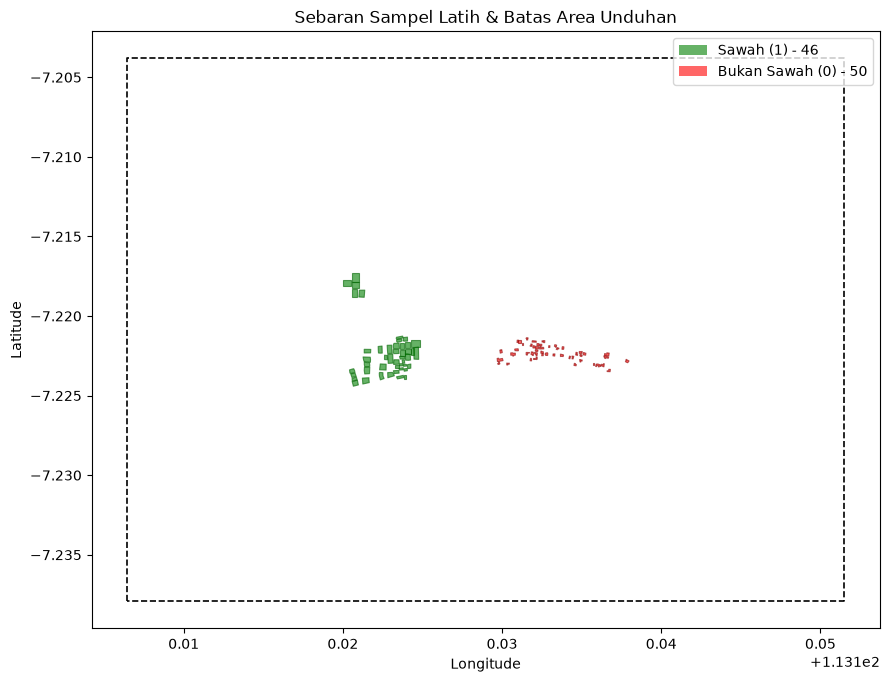

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))

# Plot non-sawah
gpd.GeoSeries([shape(g) for g in geo_bukan]).plot(
    ax=ax, facecolor="red", edgecolor="darkred", alpha=0.6, linewidth=0.8
)
# Plot sawah
gpd.GeoSeries([shape(g) for g in geo_sawah]).plot(
    ax=ax, facecolor="green", edgecolor="darkgreen", alpha=0.6, linewidth=0.8
)
# Plot bbox
gpd.GeoSeries([shp_box(*BATAS_AREA)]).boundary.plot(
    ax=ax, color="black", linestyle="--", linewidth=1.2
)

ax.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, fc="green", alpha=0.6, label=f"Sawah (1) - {len(geo_sawah)}"),
    plt.Rectangle((0, 0), 1, 1, fc="red", alpha=0.6, label=f"Bukan Sawah (0) - {len(geo_bukan)}")
], loc="best", fontsize=10)

ax.set_title("Sebaran Sampel Latih & Batas Area Unduhan")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()


## 3. Eksekusi Unduhan Citra Copernicus (Sentinel-2A L2A)

Proses pemanggilan data dilakukan dengan API **Sentinel Hub**. Jika file `sentinel2_mentah.tif` sudah eksis di folder lokal, blok kode ini akan otomatis melompat (tidak mengunduh ulang).

Alur teknis:
1. Menukarkan Client ID/Secret dengan Access Token sementara.
2. Menyortir katalog citra historis berdasarkan persentase tutupan awan terendah pada tanggal yang diset.
3. Meminta server merender spesifik area BBOX kita (format EPSG terdekat), menyaring pixel yang mengandung kabut atau awan berbekal algoritma Masking SCL.

In [6]:
if CITRA_MENTAH_TIF.exists():
    ID_KLIEN = RAHASIA_KLIEN = None
else:
    ID_KLIEN = os.environ.get("CDSE_CLIENT_ID") or input("Masukkan CDSE Client ID Anda: ").strip()
    RAHASIA_KLIEN = os.environ.get("CDSE_CLIENT_SECRET") or getpass.getpass("Masukkan CDSE Client Secret Anda: ").strip()

def ambil_token_auth():
    respon = requests.post(URL_OAUTH, data={
        "grant_type": "client_credentials",
        "client_id": ID_KLIEN,
        "client_secret": RAHASIA_KLIEN,
    }, timeout=60)
    
    if respon.status_code != 200:
        raise Exception(f"Gagal otentikasi token! Kode: {respon.status_code}. Pastikan Kredensial Valid.")
    return respon.json()["access_token"]

def cari_katalog_citra(token):
    payload = {
        "collections": ["sentinel-2-l2a"],
        "datetime": f"{TANGGAL_MULAI}T00:00:00Z/{TANGGAL_AKHIR}T23:59:59Z",
        "bbox": list(BATAS_AREA),
        "limit": 100,
    }
    header_auth = {"Authorization": f"Bearer {token}"}
    kandidat_scene = []
    
    while True:
        resp = requests.post(URL_PENCARIAN, json=payload, headers=header_auth, timeout=100)
        if resp.status_code != 200:
            raise Exception("Gagal mencari data di katalog satelit!")
            
        data_json = resp.json()
        hasil_fitur = data_json.get("features", [])
        
        url_lanjut = data_json.get("context", {}).get("next")
        
        for item in hasil_fitur:
            prop = item.get("properties", {})
            tutupan_awan = prop.get("eo:cloud_cover")
            
            if tutupan_awan is None or tutupan_awan > MAKS_AWAN_PERSEN:
                continue
            if KODE_SATELIT and not item["id"].upper().startswith(KODE_SATELIT):
                continue
                
            kandidat_scene.append((tutupan_awan, prop["datetime"], item["id"]))
            
        if not url_lanjut:
            break
        payload["next"] = url_lanjut
        
    kandidat_scene.sort() # Sortir dari yang awannya paling tipis
    catat_log(f"Ditemukan {len(kandidat_scene)} scene potensial dengan awan <= {MAKS_AWAN_PERSEN}%")
    return kandidat_scene

def tentukan_zona_utm(lon, lat):
    # Penentuan Zona EPSG UTM otomatis berdasarkan koordinat
    return (32700 if lat < 0 else 32600) + int((lon + 180) // 6) + 1

def script_evaluasi_server():
    # Perintah JavaScript untuk Copernicus memproses band spesifik
    masking = " || [0,1,3,8,9,10,11].indexOf(s.SCL) >= 0" if MASKING_AWAN else ""
    return (
        '//VERSION=3\n'
        'function setup() {\n'
        '  return {\n'
        '    input: [{bands: ["B02","B03","B04","B08","B11","B12","SCL","dataMask"]}],\n'
        '    output: {bands: 6, sampleType: "FLOAT32"}\n'
        '  };\n'
        '}\n'
        'function evaluatePixel(s) {\n'
        f'  var kotor = (s.dataMask == 0){masking};\n'
        '  if (kotor) return [0,0,0,0,0,0];\n'
        '  return [s.B02, s.B03, s.B04, s.B08, s.B11, s.B12];\n'
        '}\n'
    )

def tarik_data_spasial(token, waktu_akuisisi):
    kode_epsg = tentukan_zona_utm((BATAS_AREA[0]+BATAS_AREA[2])/2, (BATAS_AREA[1]+BATAS_AREA[3])/2)
    x_min, y_min, x_max, y_max = transform_bounds("EPSG:4326", f"EPSG:{kode_epsg}", *BATAS_AREA)
    
    # Grid 10x10 meter per piksel
    x_min, y_min = math.floor(x_min / 10) * 10, math.floor(y_min / 10) * 10
    x_max, y_max = math.ceil(x_max / 10) * 10, math.ceil(y_max / 10) * 10
    
    dt_zona = dt.datetime.fromisoformat(waktu_akuisisi.replace("Z", "+00:00")).astimezone(dt.timezone.utc)
    format_waktu = "%Y-%m-%dT%H:%M:%SZ"
    
    skema = {
        "input": {
            "bounds": {
                "bbox": [x_min, y_min, x_max, y_max],
                "properties": {"crs": f"http://www.opengis.net/def/crs/EPSG/0/{kode_epsg}"}
            },
            "data": [{
                "type": "sentinel-2-l2a",
                "dataFilter": {
                    "timeRange": {
                        "from": (dt_zona - dt.timedelta(minutes=1)).strftime(format_waktu),
                        "to": (dt_zona + dt.timedelta(minutes=1)).strftime(format_waktu)
                    },
                    "mosaickingOrder": "leastCC"
                }
            }]
        },
        "output": {
            "resx": 10, "resy": 10,
            "responses": [{"identifier": "default", "format": {"type": "image/tiff"}}]
        },
        "evalscript": script_evaluasi_server()
    }
    
    req = requests.post(URL_PROSES, json=skema, timeout=300, headers={"Authorization": f"Bearer {token}", "Accept": "image/tiff"})
    if req.status_code != 200:
        raise Exception(f"Gagal unduh dari server proses: {req.text[:200]}")
    return req.content, kode_epsg

def cek_rasio_pixel_bersih(bytes_tif):
    from rasterio.io import MemoryFile
    with MemoryFile(bytes_tif) as mem, mem.open() as dt_src:
        matriks = dt_src.read()
        return float((np.any(matriks != 0, axis=0) & np.isfinite(matriks).all(axis=0)).mean())

def mulai_rutinitas_unduh():
    if CITRA_MENTAH_TIF.exists():
        catat_log("INFO: TIF sudah eksis di penyimpanan. Mengabaikan proses download.")
        return
        
    token_aktif = ambil_token_auth()
    daftar_scene = cari_katalog_citra(token_aktif)
    
    if not daftar_scene:
        raise Exception("Tidak ada scene satelit yang memenuhi syarat di rentang waktu tersebut.")
        
    scene_pemenang = None
    
    for awan, waktu_rekam, id_scene in daftar_scene[:MAKS_PERCOBAAN_SCENE]:
        binary_tif, kode_crs = tarik_data_spasial(token_aktif, waktu_rekam)
        kualitas_piksel = cek_rasio_pixel_bersih(binary_tif)
        
        catat_log(f"> Evaluasi: {id_scene[:30]}... | {waktu_rekam} | Awan {awan:.1f}% | Kualitas Area {kualitas_piksel:.1%}")
        
        if scene_pemenang is None or kualitas_piksel > scene_pemenang["skor"]:
            scene_pemenang = dict(skor=kualitas_piksel, file=binary_tif, waktu=waktu_rekam, identitas=id_scene, awan=awan, crs=kode_crs)
            
        if kualitas_piksel >= AMBANG_VALID:
            break
            
    # Simpan hasil terbaik
    CITRA_MENTAH_TIF.write_bytes(scene_pemenang["file"])
    teks_laporan = (
        f"ID Scene Terpilih : {scene_pemenang['identitas']}\n"
        f"Tanggal Akuisisi : {scene_pemenang['waktu']}\n"
        f"Tutupan Awan Map : {scene_pemenang['awan']:.1f}%\n"
        f"Pixel Bersih : {scene_pemenang['skor']:.1%}\n"
        f"Sistem Koordinat : EPSG:{scene_pemenang['crs']}\n"
        f"Masking SCL Aktif : {MASKING_AWAN}\n"
    )
    INFO_CITRA_TXT.write_text(teks_laporan, encoding="utf-8")
    catat_log(f"SUKSES: Menyimpan {CITRA_MENTAH_TIF.name} dari scene {scene_pemenang['identitas']}.")

mulai_rutinitas_unduh()


Ditemukan 11 scene potensial dengan awan <= 30%
> Evaluasi: S2A_MSIL2A_20260720T023141_N05... | 2026-07-20T02:50:04.854Z | Awan 4.6% | Kualitas Area 100.0%
SUKSES: Menyimpan sentinel2_mentah.tif dari scene S2A_MSIL2A_20260720T023141_N0512_R046_T49MGN_20260720T083516.SAFE.


### Log Citra Terpilih
Rekapan singkat citra satelit yang berhasil dipinang oleh sistem:

In [7]:
if INFO_CITRA_TXT.exists():
    print(INFO_CITRA_TXT.read_text(encoding="utf-8"))
else:
    print("Metadata belum tersedia (mungkin Anda menggunakan TIF eksternal).")


ID Scene Terpilih : S2A_MSIL2A_20260720T023141_N0512_R046_T49MGN_20260720T083516.SAFE
Tanggal Akuisisi : 2026-07-20T02:50:04.854Z
Tutupan Awan Map : 4.6%
Pixel Bersih : 100.0%
Sistem Koordinat : EPSG:32749
Masking SCL Aktif : True



## 4. Pembacaan Array GeoTIFF

Pada langkah ini, `rasterio` digunakan untuk membuka format citra raster `.tif`. Nilai-nilai invalid dan piksel kosong (yang terhapus akibat *masking* awan) dialihfungsikan menjadi `NaN` agar nantinya tidak mengotori kalkulasi matematika indeks.

In [8]:
with rasterio.open(CITRA_MENTAH_TIF) as reader:
    matriks_awal = reader.read().astype("float32")
    crs_citra = reader.crs
    transformasi_citra = reader.transform
    
    area_korup = np.all(matriks_awal == 0, axis=0) | ~np.isfinite(matriks_awal).all(axis=0)
    matriks_awal[:, area_korup] = np.nan
    
    BANYAK_BARIS, BANYAK_KOLOM = matriks_awal.shape[1:]
    catat_log(f"Dimensi Raster: {BANYAK_KOLOM} x {BANYAK_BARIS} | CRS: {crs_citra} | Pixel NaN: {area_korup.mean():.2%}")
    
    # Dictionary mapping band untuk kemudahan akses indeks
    dict_band = dict(zip(NAMA_BAND, matriks_awal))


Dimensi Raster: 500 x 381 | CRS: EPSG:32749 | Pixel NaN: 0.01%


## 5. Penghitungan Ekstraksi Fitur (Indeks Spektral)

Band merah (B04), NIR (B08), hijau (B03) dan inframerah gelombang pendek (B11, B12) sangat membantu algoritma memetakan pantulan air dan vegetasi. Kita tambahkan turunan perhitungan indeks (NDVI, NDWI, NDBI, EVI) ke dalam koleksi vektor fitur.

- **NDVI** = Kerapatan daun klorofil.
- **NDWI** = Jumlah genangan air permukaan (sangat sensitif di sawah basah).
- **NDBI** = Deteksi aspal dan beton perumahan (pemisah non-sawah yang ampuh).
- **EVI** = Normalisasi atmosfer vegetasi rapat.

In [9]:
def kalkulasi_nd(b1, b2):
    return (b1 - b2) / (b1 + b2 + 1e-10)

matriks_ndvi = kalkulasi_nd(dict_band["B08"], dict_band["B04"])
matriks_ndwi = kalkulasi_nd(dict_band["B03"], dict_band["B08"])
matriks_ndbi = kalkulasi_nd(dict_band["B11"], dict_band["B08"])
matriks_evi = 2.5 * (dict_band["B08"] - dict_band["B04"]) / (dict_band["B08"] + 6 * dict_band["B04"] - 7.5 * dict_band["B02"] + 1)

# Menggabungkan 6 band mentah + 4 indeks = 10 dimensi variabel
kumpulan_fitur = np.concatenate([matriks_awal, np.stack([matriks_ndvi, matriks_ndwi, matriks_ndbi, matriks_evi])]).astype("float32")
KOLOM_FITUR = NAMA_BAND + ["NDVI", "NDWI", "NDBI", "EVI"]
DIMENSI_F = kumpulan_fitur.shape[0]


## 6. Integrasi Vektor ke Raster (Rasterization)

Metode pelatihan mesin memerlukan format piksel 2 dimensi. Jadi, poligon berformat vektor yang kita baca di awal tadi akan "dibakar" di atas grid raster. Piksel yang tumpang tindih dengan poligon akan mewarisi *ID* dan *Label Kelas*-nya.

In [10]:
peta_id_ke_label = {}
koleksi_shape_piksel = []
pencacah_id = 0

for list_geo, kode_kelas in ((geo_bukan, 0), (geo_sawah, 1)):
    for poligon in list_geo:
        pencacah_id += 1
        peta_id_ke_label[pencacah_id] = kode_kelas
        
        # Transformasi ulang dari EPSG:4326 ke CRS citra UTM
        geo_transform = transform_geom("EPSG:4326", crs_citra, poligon)
        koleksi_shape_piksel.append((geo_transform, pencacah_id))
        
# Proses burning poligon
masking_poligon = features.rasterize(koleksi_shape_piksel, out_shape=(BANYAK_BARIS, BANYAK_KOLOM), 
                                     transform=transformasi_citra, fill=0, dtype="int32")

# Seleksi piksel yang berada di dalam area polygon DAN bebas dari halangan awan
filter_valid_area = (masking_poligon > 0) & np.isfinite(kumpulan_fitur).all(axis=0)

daftar_id_hadir = np.unique(masking_poligon[filter_valid_area])

for kode, julukan in ((0, "Bukan Sawah"), (1, "Sawah")):
    himpunan_id = [x for x in daftar_id_hadir if peta_id_ke_label[x] == kode]
    jumlah_px_aktif = int(np.isin(masking_poligon, himpunan_id).sum())
    catat_log(f"Status Kelas {kode} ({julukan}): {len(himpunan_id)} poligon solid -> menghasilkan {jumlah_px_aktif} piksel siap olah.")


Status Kelas 0 (Bukan Sawah): 46 poligon solid -> menghasilkan 108 piksel siap olah.
Status Kelas 1 (Sawah): 46 poligon solid -> menghasilkan 563 piksel siap olah.


## 7. Segmentasi Split Data Latih & Data Uji (Train-Test Split)

Prinsip utamanya: **Pemisahan dilakukan secara spasial per-poligon**, BUKAN diacak per-piksel. Mengapa? Karena piksel yang bertetangga cenderung memilik spektrum cahaya serupa (autokorelasi spasial). Jika diacak, model akan membocorkan data (Data Leakage). 
Proporsi kita: 70% Poligon Latih, 30% Poligon Uji.

In [12]:
generator_acak = np.random.default_rng(ANGKA_RANDOM)
keranjang_id_latih = []

for jenis_kelas in (0, 1):
    identitas = [k for k in daftar_id_hadir if peta_id_ke_label[k] == jenis_kelas]
    generator_acak.shuffle(identitas)
    
    titik_potong = max(1, int(round(len(identitas) * RASIO_LATIH)))
    keranjang_id_latih.extend(identitas[:titik_potong])
    
mask_training = filter_valid_area & np.isin(masking_poligon, keranjang_id_latih)
mask_testing = filter_valid_area & ~mask_training

pemetaan_label_citra = np.zeros(masking_poligon.max() + 1, dtype="uint8")
for param_id, param_kls in peta_id_ke_label.items():
    pemetaan_label_citra[param_id] = param_kls
    
# Menyiapkan matrix prediktor (X) dan target (y)
Matriks_X_Train, Matriks_y_Train = kumpulan_fitur[:, mask_training].T, pemetaan_label_citra[masking_poligon[mask_training]]
Matriks_X_Test, Matriks_y_Test = kumpulan_fitur[:, mask_testing].T, pemetaan_label_citra[masking_poligon[mask_testing]]

catat_log(f"Distribusi Piksel -> Training Set: {len(Matriks_y_Train)} | Testing Set: {len(Matriks_y_Test)}")


Distribusi Piksel -> Training Set: 464 | Testing Set: 207


## 8. Membangun Model Random Forest dan Uji Kemampuan

`RandomForestClassifier` akan diinstruksikan membangun ratusan (N=200) skenario pohon klasifikasi menggunakan `class_weight='balanced'`. Penggunaan pembobot sangat penting di sini, menimbang piksel area non-sawah jauh lebih dominan dibanding area sawah meskipun jumlah poligon sama (ukuran persawahan sempit).

In [13]:
# Pembangunan struktur model
model_rf_awal = RandomForestClassifier(n_estimators=JUMLAH_POHON, random_state=ANGKA_RANDOM, class_weight="balanced", n_jobs=-1)
model_rf_awal.fit(Matriks_X_Train, Matriks_y_Train)

# Evaluasi buta menggunakan set data pengujian
prediksi_ujian = model_rf_awal.predict(Matriks_X_Test)

catat_log(">>> MATRIKS KEBINGUNGAN (Confusion Matrix):")
catat_log(confusion_matrix(Matriks_y_Test, prediksi_ujian, labels=[0, 1]))
catat_log(f"Akurasi Keseluruhan : {accuracy_score(Matriks_y_Test, prediksi_ujian):.3f}")
catat_log(f"Indeks Kesepakatan (Kappa) : {cohen_kappa_score(Matriks_y_Test, prediksi_ujian):.3f}")

catat_log("\n>>> TABEL LAPORAN KLASIFIKASI:")
catat_log(classification_report(Matriks_y_Test, prediksi_ujian, target_names=["Bukan Sawah", "Sawah"], digits=3))

catat_log(">>> KEKUATAN INDIKATOR (Feature Importances):")
deret_kekuatan = np.argsort(model_rf_awal.feature_importances_)[::-1]
for index_feat in deret_kekuatan:
    catat_log(f"  {KOLOM_FITUR[index_feat]:<6s}: {model_rf_awal.feature_importances_[index_feat]:.4f}")


>>> MATRIKS KEBINGUNGAN (Confusion Matrix):
[[ 32   3]
 [  0 172]]
Akurasi Keseluruhan : 0.986
Indeks Kesepakatan (Kappa) : 0.947

>>> TABEL LAPORAN KLASIFIKASI:
              precision    recall  f1-score   support

 Bukan Sawah      1.000     0.914     0.955        35
       Sawah      0.983     1.000     0.991       172

    accuracy                          0.986       207
   macro avg      0.991     0.957     0.973       207
weighted avg      0.986     0.986     0.985       207

>>> KEKUATAN INDIKATOR (Feature Importances):
  B04   : 0.3099
  B12   : 0.2225
  NDVI  : 0.1781
  EVI   : 0.1071
  B11   : 0.0562
  B03   : 0.0418
  B02   : 0.0303
  NDWI  : 0.0222
  B08   : 0.0163
  NDBI  : 0.0156


## 9. Prediksi ke Seluruh Permukaan Peta (Raster Inference)

Setelah metrik di atas dipastikan bagus (Kappa dan F1-Score memadai), model akan dilatih *ulang* menggunakan **gabungan seluruh dataset** agar memori polanya maksimum. Setelah itu, piksel seluruh area `BBOX` yang berhasil didownload akan ditebak kelasnya. Piksel NaN dicap nilai khusus `255` (nodata).

In [14]:
# Fit ulang memakai semua set
model_rf_final = RandomForestClassifier(n_estimators=JUMLAH_POHON, random_state=ANGKA_RANDOM, class_weight="balanced", n_jobs=-1)
model_rf_final.fit(kumpulan_fitur[:, filter_valid_area].T, pemetaan_label_citra[masking_poligon[filter_valid_area]])

# Flatten grid
grid_mendatar = kumpulan_fitur.reshape(DIMENSI_F, -1).T
piksel_berisi = np.isfinite(grid_mendatar).all(axis=1)

matriks_keputusan = np.full(grid_mendatar.shape[0], 255, dtype="uint8")
matriks_keputusan[piksel_berisi] = model_rf_final.predict(grid_mendatar[piksel_berisi]).astype("uint8")

hasil_grid_2d = matriks_keputusan.reshape(BANYAK_BARIS, BANYAK_KOLOM)

if crs_citra.is_projected:
    luas_sepetak = abs(transformasi_citra.a * transformasi_citra.e)
    catat_log(f"Est. Luas Sawah Ditemukan : {(hasil_grid_2d == 1).sum() * luas_sepetak / 10000:.2f} Hektar")
    catat_log(f"Est. Luas Area Lainnya    : {(hasil_grid_2d == 0).sum() * luas_sepetak / 10000:.2f} Hektar")


Est. Luas Sawah Ditemukan : 1778.57 Hektar
Est. Luas Area Lainnya    : 126.31 Hektar


## 10. Penyimpanan Output GeoTIFF dan Pratinjau Citra

Sesi pungkasan menyimpan array `hasil_grid_2d` kembali ke format raster TIF. Penyesuaian `colormap` *(0: Merah, 1: Hijau)* ditanamkan ke metadata file agar warna standar muncul ketika dirender di aplikasi sistem informasi geografi seperti QGIS atau ArcGIS.

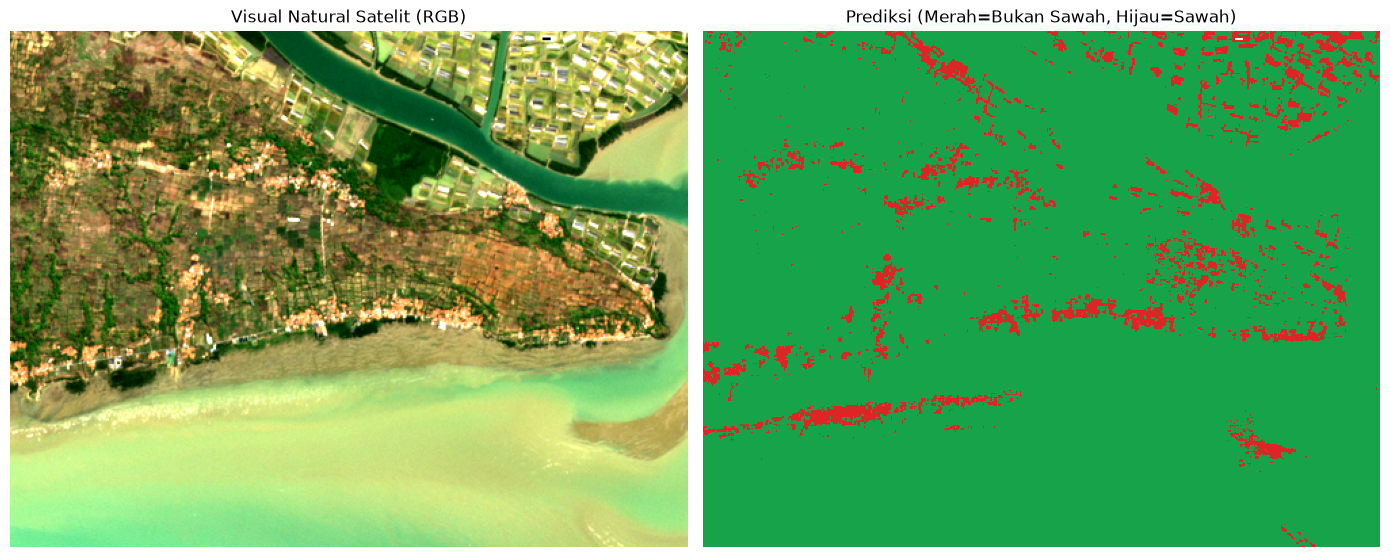

Misi rampung!


In [15]:
with rasterio.open(HASIL_TIF, "w", driver="GTiff", height=BANYAK_BARIS, width=BANYAK_KOLOM, count=1,
                   dtype="uint8", crs=crs_citra, transform=transformasi_citra, nodata=255, compress="lzw") as tulis_tif:
    tulis_tif.write(hasil_grid_2d, 1)
    tulis_tif.set_band_description(1, "Segmentasi [0: Non-sawah, 1: Sawah]")
    tulis_tif.write_colormap(1, {0: (220, 38, 38, 255), 1: (22, 163, 74, 255), 255: (0, 0, 0, 0)})

# Merender tampilan asli satelit B04-B03-B02
spektrum_rgb = np.dstack([dict_band["B04"], dict_band["B03"], dict_band["B02"]])
ambang_bawah, ambang_atas = np.nanpercentile(spektrum_rgb, 2), np.nanpercentile(spektrum_rgb, 98)
spektrum_rgb = np.nan_to_num(np.clip((spektrum_rgb - ambang_bawah) / (ambang_atas - ambang_bawah + 1e-10), 0, 1))

fig, kol = plt.subplots(1, 2, figsize=(14, 6))
kol[0].imshow(spektrum_rgb)
kol[0].set_title("Visual Natural Satelit (RGB)")
kol[0].axis("off")

kol[1].imshow(np.ma.masked_equal(hasil_grid_2d, 255), cmap=ListedColormap(["#dc2626", "#16a34a"]), vmin=0, vmax=1, interpolation="nearest")
kol[1].set_title("Prediksi (Merah=Bukan Sawah, Hijau=Sawah)")
kol[1].axis("off")

plt.tight_layout()
plt.savefig(HASIL_GAMBAR, dpi=180)
plt.show()

HASIL_TEKS.write_text("\n".join(REKAMAN_LOG), encoding="utf-8")
catat_log("Misi rampung!")
